# Customer Intelligence & Segmentation

## Objective

Identify meaningful customer segments based on purchasing behavior.

### Approach

1. Load the cleaned retail dataset
2. Build customer-level RFM features
3. Transform and scale the features
4. Determine an appropriate number of clusters
5. Apply K-Means clustering
6. Profile and visualize customer segments

### RFM Metrics

- **Recency** — How recently a customer purchased
- **Frequency** — How often a customer purchased
- **Monetary** — How much a customer spent

In [1]:
# Cell 2: Load and prepare data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

file_path = "../data/processed/online_retail_clean.csv"

df = pd.read_csv(file_path)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Customer analysis requires a known Customer ID
customer_df = df.dropna(subset=["Customer ID"]).copy()

customer_df["Customer ID"] = customer_df["Customer ID"].astype(int)

print("Dataset shape:", df.shape)
print("Customer analysis rows:", customer_df.shape[0])
print("Unique customers:", customer_df["Customer ID"].nunique())

Dataset shape: (1007913, 9)
Customer analysis rows: 779425
Unique customers: 5878


/var/folders/sj/rw1skm1j5hg2bbbhk0sytpq40000gn/T/ipykernel_3660/3046414919.py:14: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [2]:
# Cell 3: RFM Analysis

analysis_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM dataset shape:", rfm.shape)

display(rfm.head())

print("\nRFM statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


RFM dataset shape: (5878, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40



RFM statistics:


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289724,2955.904095
std,209.338707,13.009830,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


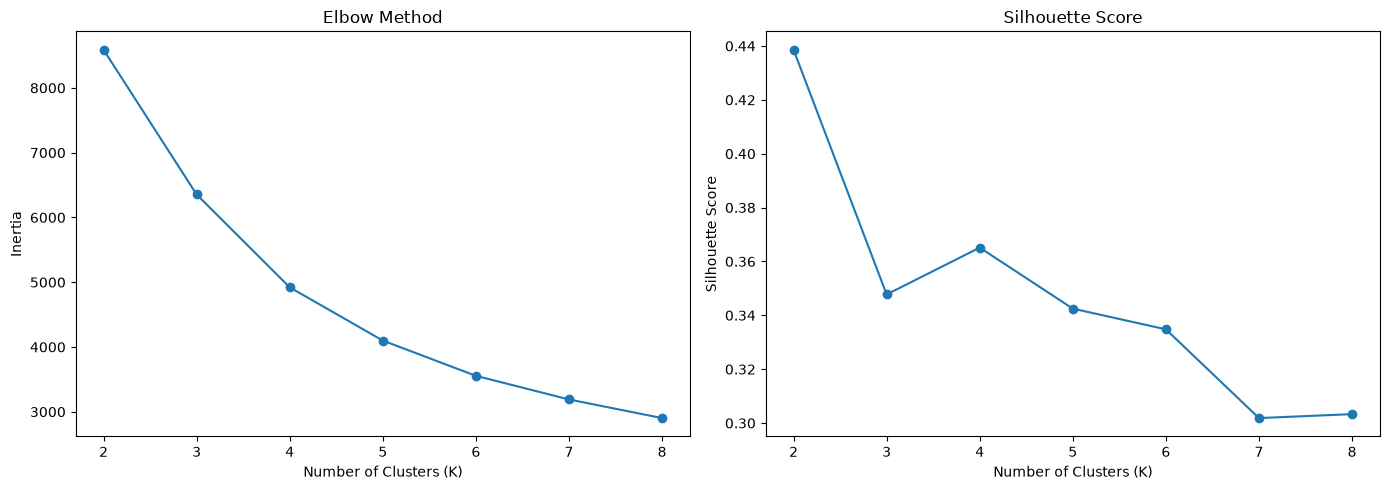

Best K according to silhouette score: 2


In [3]:
# Cell 4: Transform features and determine optimal clusters

rfm_features = ["Recency", "Frequency", "Monetary"]

# Log transformation reduces extreme skew
rfm_log = np.log1p(rfm[rfm_features])

# Standardize features so they are comparable
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Test different numbers of clusters
k_values = range(2, 9)

inertia = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(rfm_scaled)
    
    inertia.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

# Plot elbow + silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best K according to silhouette score:", best_k)

CUSTOMER SEGMENT PROFILE


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
1,2320,50.56,12.72,6546.97
0,3558,299.65,2.10,614.34


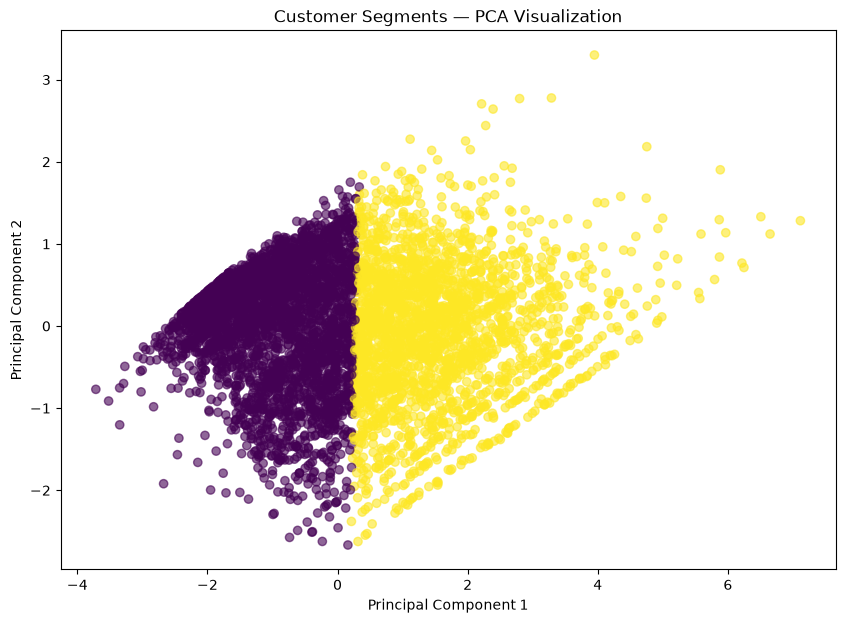


Customer segmentation saved successfully!
File: ../data/processed/customer_segments.csv


In [4]:
# Cell 5: Final K-Means clustering and segment profiling

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Profile each cluster
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
    .sort_values("Avg_Monetary", ascending=False)
)

print("CUSTOMER SEGMENT PROFILE")
display(cluster_profile)

# PCA for 2D visualization
pca = PCA(n_components=2, random_state=42)

rfm_pca = pca.fit_transform(rfm_scaled)

plt.figure(figsize=(10, 7))

plt.scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=rfm["Cluster"],
    alpha=0.6
)

plt.title("Customer Segments — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Save customer segmentation results
output_path = "../data/processed/customer_segments.csv"

rfm.to_csv(output_path, index=False)

print("\nCustomer segmentation saved successfully!")
print("File:", output_path)

In [5]:
# Cell 5: Compare K=3 and K=4

for k in [3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    
    temp_rfm = rfm.copy()
    temp_rfm["Cluster"] = labels
    
    profile = (
        temp_rfm
        .groupby("Cluster")
        .agg(
            Customers=("Customer ID", "count"),
            Avg_Recency=("Recency", "mean"),
            Avg_Frequency=("Frequency", "mean"),
            Avg_Monetary=("Monetary", "mean")
        )
        .round(2)
        .sort_values("Avg_Monetary", ascending=False)
    )
    
    print(f"\n{'='*55}")
    print(f"K = {k} | Silhouette Score = {score:.3f}")
    print(f"{'='*55}")
    display(profile)


K = 3 | Silhouette Score = 0.348


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
1,1216,33.44,19.24,10667.21
2,2260,107.75,4.37,1526.96
0,2402,374.37,1.55,396.56



K = 4 | Silhouette Score = 0.365


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
3,1192,27.55,19.31,10755.97
2,1462,229.26,5.08,1954.20
1,1250,28.31,3.05,855.51
0,1974,395.15,1.38,317.76


FINAL CUSTOMER SEGMENTATION


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,
Champions,NaN,NaN,NaN,NaN
Recent / Developing,1250.0,28.31,3.05,855.51
At Risk,1462.0,229.26,5.08,1954.20
Inactive,1974.0,395.15,1.38,317.76


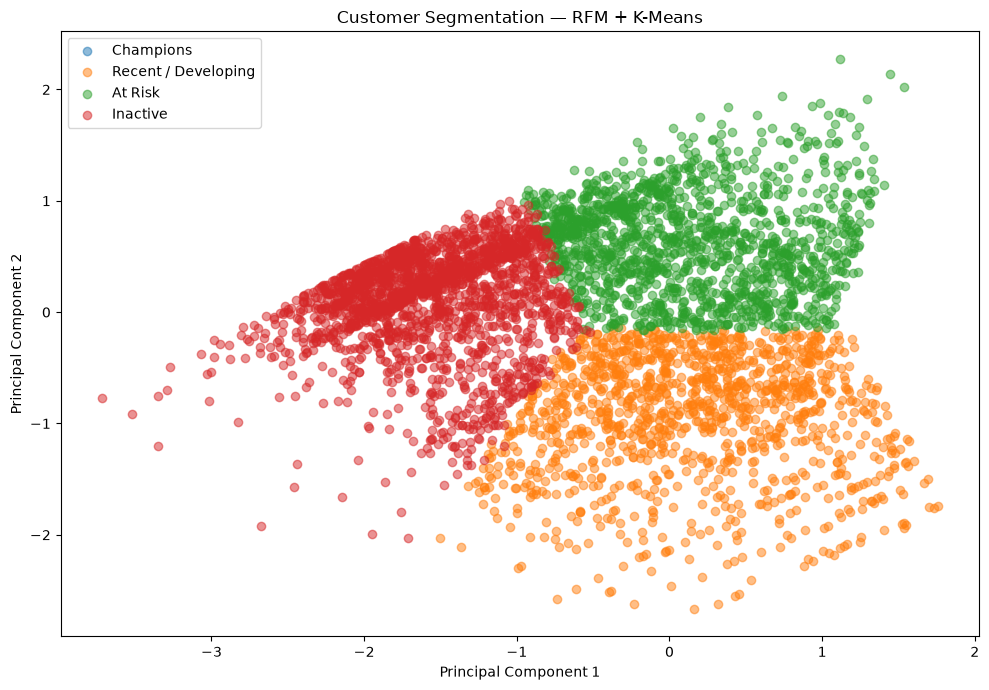


Customer segmentation saved successfully!
File: ../data/processed/customer_segments.csv
Customers: 5878
Final clusters: 4


In [6]:
# Cell 5: Final Customer Segmentation

final_k = 4

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans_final.fit_predict(rfm_scaled)

# ---------------------------------------------------------
# Build cluster profile
# ---------------------------------------------------------

cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
)

# ---------------------------------------------------------
# Dynamically assign business-friendly segment names
# ---------------------------------------------------------

profile = cluster_profile.copy()

# Percentile ranks for each metric
profile["Recency_Rank"] = profile["Avg_Recency"].rank(pct=True)
profile["Frequency_Rank"] = profile["Avg_Frequency"].rank(pct=True)
profile["Monetary_Rank"] = profile["Avg_Monetary"].rank(pct=True)

# High-value + recent = Champion
profile["Champion_Score"] = (
    (1 - profile["Recency_Rank"])
    + profile["Frequency_Rank"]
    + profile["Monetary_Rank"]
)

champion_cluster = profile["Champion_Score"].idxmax()

# High recency + low activity/value = Inactive
profile["Inactive_Score"] = (
    profile["Recency_Rank"]
    + (1 - profile["Frequency_Rank"])
    + (1 - profile["Monetary_Rank"])
)

inactive_cluster = profile["Inactive_Score"].idxmax()

# Remaining clusters
remaining_clusters = [
    c for c in profile.index
    if c not in [champion_cluster, inactive_cluster]
]

# Lower recency among remaining = Recent / Developing
recent_cluster = profile.loc[
    remaining_clusters, "Avg_Recency"
].idxmin()

# Other remaining cluster = At Risk
at_risk_cluster = [
    c for c in remaining_clusters
    if c != recent_cluster
][0]

segment_names = {
    champion_cluster: "High-Value Customers",
    at_risk_cluster: "At Risk",
    recent_cluster: "Recent / Developing",
    inactive_cluster: "Inactive"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

# ---------------------------------------------------------
# Final segment profile
# ---------------------------------------------------------

segment_profile = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

segment_order = [
    "Champions",
    "Recent / Developing",
    "At Risk",
    "Inactive"
]

segment_profile = segment_profile.reindex(segment_order)

print("=" * 60)
print("FINAL CUSTOMER SEGMENTATION")
print("=" * 60)

display(segment_profile)

# ---------------------------------------------------------
# PCA visualization
# ---------------------------------------------------------

pca = PCA(n_components=2, random_state=42)

rfm_pca = pca.fit_transform(rfm_scaled)

plt.figure(figsize=(10, 7))

for segment in segment_order:

    mask = rfm["Segment"] == segment

    plt.scatter(
        rfm_pca[mask, 0],
        rfm_pca[mask, 1],
        alpha=0.5,
        label=segment
    )

plt.title("Customer Segmentation — RFM + K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

output_path = "../data/processed/customer_segments.csv"

rfm.to_csv(
    output_path,
    index=False
)

print("\nCustomer segmentation saved successfully!")
print("File:", output_path)
print("Customers:", len(rfm))
print("Final clusters:", final_k)